# Project 19: Retail Pricing, Promotion & Profitability
**Beginner-friendly Google Colab notebook**

We study prices, discounts, revenue, estimated costs, profit, and promotion comparisons using a public retail transaction dataset.

**Important:** Kaggle data may not include real costs or promotion flags. This notebook simulates those fields using documented assumptions, so findings are illustrative, not causal proof.

Dataset: [Kaggle Online Retail Transactions](https://www.kaggle.com/datasets/abhishekrp1517/online-retail-transactions)
Download the CSV, then upload it when prompted below.

In [1]:
# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print("Ready!")

Ready!


## 2. Load the Kaggle dataset automatically
This dataset was uploaded from Kaggle and mirrored publicly. The code below downloads the CSV directly in Colab—so **you do not need to upload the file manually**.

Original Kaggle source: https://www.kaggle.com/datasets/abhishekrp1517/online-retail-transactions
Public mirror: https://huggingface.co/datasets/jason1966/abhishekrp1517_online-retail-transactions-dataset

In [2]:
# Load the Kaggle dataset automatically from a public mirror
# The dataset was originally uploaded from Kaggle; this mirror allows Colab to load it without manual upload.
dataset_url = "https://huggingface.co/datasets/jason1966/abhishekrp1517_online-retail-transactions-dataset/resolve/main/Online%20Retail.csv"

df = pd.read_csv(dataset_url, encoding="latin1")
print("Dataset loaded automatically!")
print("Rows and columns:", df.shape)
df.head()

Dataset loaded automatically!
Rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [3]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680,France


## 3. Identify column names

In [4]:
df.columns = [str(c).strip() for c in df.columns]
print(df.columns.tolist())

def find_column(possible_names):
    for name in possible_names:
        for col in df.columns:
            clean_col = col.lower().replace(" ", "").replace("_", "")
            clean_name = name.lower().replace(" ", "").replace("_", "")
            if clean_col == clean_name:
                return col
    return None

date_col = find_column(["InvoiceDate", "Date", "TransactionDate", "OrderDate"])
product_col = find_column(["StockCode", "Product", "ProductID", "Item", "Description"])
quantity_col = find_column(["Quantity", "Qty", "UnitsSold"])
price_col = find_column(["UnitPrice", "Price", "SellingPrice"])
market_col = find_column(["Country", "Store", "StoreName", "Location"])

print("Date:", date_col, "| Product:", product_col,
      "| Quantity:", quantity_col, "| Price:", price_col, "| Market:", market_col)

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
Date: InvoiceDate | Product: StockCode | Quantity: Quantity | Price: UnitPrice | Market: Country


## 4. Create a clean table

In [5]:
sales = pd.DataFrame()
sales["date"] = pd.to_datetime(df[date_col], errors="coerce")
sales["product"] = df[product_col].astype(str)
sales["quantity"] = pd.to_numeric(df[quantity_col], errors="coerce")
sales["unit_price"] = pd.to_numeric(df[price_col], errors="coerce")
sales["market"] = df[market_col].astype(str) if market_col else "Unknown"

sales = sales.dropna(subset=["date", "product", "quantity", "unit_price"])
print("Clean rows:", sales.shape)
sales.head()

Clean rows: (541909, 5)


,date,product,quantity,unit_price,market
0,2010-12-01 08:26:00,85123A,6,2.55,United Kingdom
1,2010-12-01 08:26:00,71053,6,3.39,United Kingdom
2,2010-12-01 08:26:00,84406B,8,2.75,United Kingdom
3,2010-12-01 08:26:00,84029G,6,3.39,United Kingdom
4,2010-12-01 08:26:00,84029E,6,3.39,United Kingdom


## 5. Validate price, quantity and returns

In [6]:
print("Missing values:", sales.isna().sum().sum())
print("Zero quantity rows:", (sales["quantity"] == 0).sum())
print("Invalid prices:", (sales["unit_price"] <= 0).sum())
print("Return rows (negative quantity):", (sales["quantity"] < 0).sum())

sales = sales[sales["unit_price"] > 0].copy()
sales["is_return"] = sales["quantity"] < 0

Missing values: 0
Zero quantity rows: 0
Invalid prices: 2517
Return rows (negative quantity): 10624


## 6. Simulate cost and promotions
Assumptions: estimated product cost is 50–80% of typical price; 25% of rows are promotional; promotional discount is 5–25%. These values are simulated because they may not exist in the Kaggle source. Random seed makes the simulation repeatable.

In [7]:
np.random.seed(42)
typical_price = sales.groupby("product")["unit_price"].median()
sales["typical_price"] = sales["product"].map(typical_price)

products = sales["product"].unique()
cost_ratios = pd.Series(np.random.uniform(0.50, 0.80, len(products)), index=products)
sales["cost_ratio"] = sales["product"].map(cost_ratios)
sales["unit_cost"] = sales["typical_price"] * sales["cost_ratio"]

sales["promotion"] = np.random.choice(
    ["No Promotion", "Promotion"], len(sales), p=[0.75, 0.25]
)
sales["discount_pct"] = np.where(
    sales["promotion"] == "Promotion",
    np.random.uniform(0.05, 0.25, len(sales)),
    0
)
sales["selling_price"] = sales["unit_price"] * (1 - sales["discount_pct"])
sales.head()

,date,product,quantity,unit_price,market,is_return,typical_price,cost_ratio,unit_cost,promotion,discount_pct,selling_price
0,2010-12-01 08:26:00,85123A,6,2.55,United Kingdom,False,2.95,0.612362,1.806468,No Promotion,0.000000,2.550000
1,2010-12-01 08:26:00,71053,6,3.39,United Kingdom,False,3.75,0.785214,2.944554,No Promotion,0.000000,3.390000
2,2010-12-01 08:26:00,84406B,8,2.75,United Kingdom,False,4.15,0.719598,2.986332,Promotion,0.199133,2.202385
3,2010-12-01 08:26:00,84029G,6,3.39,United Kingdom,False,4.25,0.679598,2.888290,Promotion,0.109909,3.017409
4,2010-12-01 08:26:00,84029E,6,3.39,United Kingdom,False,4.25,0.546806,2.323924,No Promotion,0.000000,3.390000


## 7. Calculate revenue, discount, cost and profit

In [8]:
# Negative quantities are returns and reduce sales/revenue/cost
sales["gross_revenue"] = sales["quantity"] * sales["unit_price"]
sales["discount_amount"] = sales["quantity"] * sales["unit_price"] * sales["discount_pct"]
sales["net_revenue"] = sales["quantity"] * sales["selling_price"]
sales["cost_of_goods"] = sales["quantity"] * sales["unit_cost"]
sales["gross_profit"] = sales["net_revenue"] - sales["cost_of_goods"]

sales["margin_pct"] = np.where(
    sales["net_revenue"] != 0,
    sales["gross_profit"] / sales["net_revenue"] * 100,
    np.nan
)
sales["month"] = sales["date"].dt.to_period("M").astype(str)
sales[["product", "quantity", "unit_price", "discount_pct",
       "net_revenue", "cost_of_goods", "gross_profit"]].head()

,product,quantity,unit_price,discount_pct,net_revenue,cost_of_goods,gross_profit
0,85123A,6,2.55,0.000000,15.300000,10.838808,4.461192
1,71053,6,3.39,0.000000,20.340000,17.667322,2.672678
2,84406B,8,2.75,0.199133,17.619076,23.890660,-6.271583
3,84029G,6,3.39,0.109909,18.104453,17.329737,0.774715
4,84029E,6,3.39,0.000000,20.340000,13.943543,6.396457


## 8. Overall summary

In [9]:
total_revenue = sales["net_revenue"].sum()
total_profit = sales["gross_profit"].sum()
overall_margin = total_profit / total_revenue * 100 if total_revenue else np.nan

summary = pd.DataFrame({
    "Metric": ["Units (net)", "Gross Revenue", "Discount Amount",
              "Net Revenue", "Estimated Cost", "Gross Profit", "Gross Margin %"],
    "Value": [sales["quantity"].sum(), sales["gross_revenue"].sum(),
              sales["discount_amount"].sum(), total_revenue,
              sales["cost_of_goods"].sum(), total_profit, overall_margin]
})
summary

,Metric,Value
0,Units (net),5.310802e+06
1,Gross Revenue,9.769872e+06
2,Discount Amount,3.783621e+05
3,Net Revenue,9.391510e+06
4,Estimated Cost,6.489784e+06
5,Gross Profit,2.901726e+06
6,Gross Margin %,3.089734e+01


## 9. Product scorecard

In [10]:
product_scorecard = sales.groupby("product").agg(
    units=("quantity", "sum"),
    revenue=("net_revenue", "sum"),
    cost=("cost_of_goods", "sum"),
    profit=("gross_profit", "sum"),
    average_price=("selling_price", "mean"),
    average_discount=("discount_pct", "mean")
).reset_index()
product_scorecard["margin_pct"] = np.where(
    product_scorecard["revenue"] != 0,
    product_scorecard["profit"] / product_scorecard["revenue"] * 100,
    np.nan
)
product_scorecard.sort_values("profit", ascending=False).head(15)

,product,units,revenue,cost,profit,average_price,average_discount,margin_pct
3927,DOT,705,197148.815519,72183.425191,124965.390327,278.861946,0.043731,63.386326
1387,22502,1865,50434.514824,7655.985579,42778.529245,9.922568,0.036660,84.819948
3421,85123A,35082,94548.554203,63374.510558,31174.043645,2.992826,0.038279,32.971465
1009,22086,18902,62163.299990,33094.837043,29068.462947,3.224907,0.037870,46.761454
1313,22423,13022,159127.932299,132656.883713,26471.048586,13.302146,0.037055,16.635074
3930,POST,3003,63419.055349,37770.593868,25648.461481,36.089381,0.040509,40.442831
2949,84347,100,24993.358577,178.005099,24815.353478,3.267003,0.037310,99.287790
2675,47566,18018,94636.925285,71150.163097,23486.762188,5.555133,0.038637,24.817757
1037,22114,5665,31554.738079,13453.684717,18101.053362,4.825428,0.036460,57.363979
2851,79321,10226,51687.737862,33841.151931,17846.585931,6.537385,0.034404,34.527698


## 10. Market, month and channel/market comparison

In [11]:
market_scorecard = sales.groupby("market").agg(
    units=("quantity", "sum"), revenue=("net_revenue", "sum"),
    profit=("gross_profit", "sum")
).reset_index().sort_values("profit", ascending=False)

monthly_scorecard = sales.groupby("month").agg(
    units=("quantity", "sum"), revenue=("net_revenue", "sum"),
    profit=("gross_profit", "sum"), discount=("discount_amount", "sum")
).reset_index()

display(market_scorecard.head(10))
display(monthly_scorecard.head(12))

,market,units,revenue,profit
36,United Kingdom,4399357,7.889324e+06,2.507582e+06
10,EIRE,142363,2.527137e+05,6.306257e+04
14,Germany,117446,2.131033e+05,5.922852e+04
24,Netherlands,199552,2.745595e+05,5.560945e+04
13,France,110479,1.906370e+05,5.518815e+04
0,Australia,83345,1.328603e+05,2.943837e+04
33,Switzerland,30324,5.440539e+04,1.644108e+04
31,Spain,26813,5.276158e+04,1.533830e+04
32,Sweden,35637,3.488088e+04,1.149609e+04
3,Belgium,23152,3.940560e+04,1.128447e+04


,month,units,revenue,profit,discount
0,2010-12,343197,7.227158e+05,258630.840799,26241.181874
1,2011-01,307940,5.361110e+05,127049.804759,23889.222664
2,2011-02,280684,4.782548e+05,142043.053979,19807.808617
3,2011-03,372131,6.584263e+05,221534.232422,24840.801256
4,2011-04,295170,4.726318e+05,146692.610667,20575.271679
5,2011-05,389870,6.951138e+05,211512.673853,28219.701976
6,2011-06,381851,6.684737e+05,187212.007643,22649.466009
7,2011-07,395731,6.554101e+05,187803.219180,25889.968271
8,2011-08,409424,6.805905e+05,221021.824079,24214.172303
9,2011-09,563391,9.796960e+05,294187.986991,39991.610537


## 11. Promotion vs no-promotion comparison
This is a descriptive comparison. Promotion labels are simulated, so it cannot establish real promotion lift.

In [12]:
promotion_comparison = sales.groupby("promotion").agg(
    rows=("quantity", "count"), units=("quantity", "sum"),
    avg_discount=("discount_pct", "mean"), revenue=("net_revenue", "sum"),
    profit=("gross_profit", "sum"), avg_price=("selling_price", "mean")
).reset_index()
promotion_comparison["margin_pct"] = np.where(
    promotion_comparison["revenue"] != 0,
    promotion_comparison["profit"] / promotion_comparison["revenue"] * 100,
    np.nan
)
promotion_comparison

,promotion,rows,units,avg_discount,revenue,profit,avg_price,margin_pct
0,No Promotion,404604,3906924,0.00000,7.190896e+06,2.406929e+06,4.607884,33.471893
1,Promotion,134788,1403878,0.15024,2.200614e+06,4.947975e+05,4.142889,22.484518


### Compare promotion groups within each month (seasonality check)

In [13]:
monthly_promo = sales.groupby(["month", "promotion"]).agg(
    rows=("quantity", "count"), units=("quantity", "sum"),
    revenue=("net_revenue", "sum"), profit=("gross_profit", "sum")
).reset_index()
monthly_promo.head(20)

,month,promotion,rows,units,revenue,profit
0,2010-12,No Promotion,31732,255703,564053.280000,222312.111647
1,2010-12,Promotion,10476,87494,158662.558126,36318.729152
2,2011-01,No Promotion,26230,228977,405029.800000,103783.356426
3,2011-01,Promotion,8777,78963,131081.237336,23266.448333
4,2011-02,No Promotion,20688,210609,367365.500000,119355.793548
5,2011-02,Promotion,6892,70075,110889.341383,22687.260431
6,2011-03,No Promotion,27301,280330,517025.010000,187464.650624
7,2011-03,Promotion,9201,91801,141401.268744,34069.581798
8,2011-04,No Promotion,22271,216523,360622.690000,121637.395651
9,2011-04,Promotion,7384,78647,112009.159321,25055.215015


## 12. NumPy elasticity-style estimate

In [14]:
# Simple comparison of average price and quantity. Not a causal estimate.
g = sales.groupby("promotion").agg(
    average_price=("selling_price", "mean"),
    average_quantity_per_row=("quantity", "mean")
)
display(g)

if "Promotion" in g.index and "No Promotion" in g.index:
    price0 = g.loc["No Promotion", "average_price"]
    price1 = g.loc["Promotion", "average_price"]
    qty0 = g.loc["No Promotion", "average_quantity_per_row"]
    qty1 = g.loc["Promotion", "average_quantity_per_row"]
    pct_price = (price1-price0)/price0 if price0 else np.nan
    pct_qty = (qty1-qty0)/qty0 if qty0 else np.nan
    elasticity_style = pct_qty/pct_price if pct_price != 0 else np.nan
    print("Price change %:", round(pct_price*100, 2))
    print("Quantity change %:", round(pct_qty*100, 2))
    print("Elasticity-style number:", round(elasticity_style, 3))
else:
    print("Both groups were not present.")

,average_price,average_quantity_per_row
promotion,,
No Promotion,4.607884,9.656168
Promotion,4.142889,10.415452


Price change %: -10.09
Quantity change %: 7.86
Elasticity-style number: -0.779


## 13. Discount scenario simulation
We test 0%, 5%, 10%, 15%, 20%, and 25% discounts for top products. Assumed elasticity is -1.5: lower prices are assumed to raise volume. This is an assumption for practice, not measured customer behaviour.

In [15]:
top_products = sales.groupby("product")["net_revenue"].sum().nlargest(10).index
base = sales[sales["product"].isin(top_products)].groupby("product").agg(
    base_price=("unit_price", "mean"),
    unit_cost=("unit_cost", "mean"),
    base_units=("quantity", "sum")
).reset_index()

discounts = [0, 0.05, 0.10, 0.15, 0.20, 0.25]
assumed_elasticity = -1.5
rows = []

for _, r in base.iterrows():
    for d in discounts:
        price_ratio = 1 - d
        volume_multiplier = price_ratio ** assumed_elasticity
        projected_units = r["base_units"] * volume_multiplier
        projected_price = r["base_price"] * price_ratio
        projected_revenue = projected_units * projected_price
        projected_cost = projected_units * r["unit_cost"]
        projected_profit = projected_revenue - projected_cost
        rows.append({
            "product": r["product"], "discount_pct": d*100,
            "projected_units": projected_units,
            "projected_revenue": projected_revenue,
            "projected_cost": projected_cost,
            "projected_profit": projected_profit
        })

scenario_report = pd.DataFrame(rows)
scenario_report.head(20)

,product,discount_pct,projected_units,projected_revenue,projected_cost,projected_profit
0,22086,0.0,18902.000000,63343.570083,33094.837043,30248.733040
1,22086,5.0,20413.729275,64989.131649,35741.669865,29247.461784
2,22086,10.0,22138.286049,66769.985529,38761.134758,28008.850771
3,22086,15.0,24120.114786,68705.748289,42231.047948,26474.700342
4,22086,20.0,26416.348069,70820.264321,46251.440833,24568.823489
5,22086,25.0,29101.532769,73142.854477,50952.834868,22190.019609
6,22423,0.0,13022.000000,179870.729490,132656.883713,47213.845777
7,22423,5.0,14063.463264,184543.474631,143266.411521,41277.063110
8,22423,10.0,15251.548034,189600.396529,155369.592531,34230.803997
9,22423,15.0,16616.873069,195097.198483,169278.344216,25818.854267


## 14. Identify possible margin erosion

In [16]:
margin_check = sales.groupby(["product", "promotion"]).agg(
    revenue=("net_revenue", "sum"), profit=("gross_profit", "sum"),
    average_discount=("discount_pct", "mean")
).reset_index()
margin_check["margin_pct"] = np.where(
    margin_check["revenue"] != 0,
    margin_check["profit"] / margin_check["revenue"] * 100,
    np.nan
)
margin_check.sort_values("margin_pct").head(15)

,product,promotion,revenue,profit,average_discount,margin_pct
127,16219,Promotion,46.430711,-299.637274,0.163398,-645.342844
3777,23057,Promotion,66.711106,-306.082319,0.169766,-458.817638
2001,22105,Promotion,-134.049739,584.104125,0.116718,-435.736861
6123,84827,Promotion,6.281747,-25.709066,0.162055,-409.266188
432,20818,Promotion,11.776417,-43.304841,0.057887,-367.725096
5987,84686,Promotion,5.882808,-19.876588,0.069176,-337.875852
1995,22102,Promotion,-192.005295,601.473847,0.150043,-313.258990
115,16202E,No Promotion,0.950000,-2.804106,0.000000,-295.169055
4992,35957,Promotion,85.477666,-250.646995,0.134919,-293.230977
126,16219,No Promotion,349.060000,-993.008528,0.000000,-284.480756


## 15. Charts

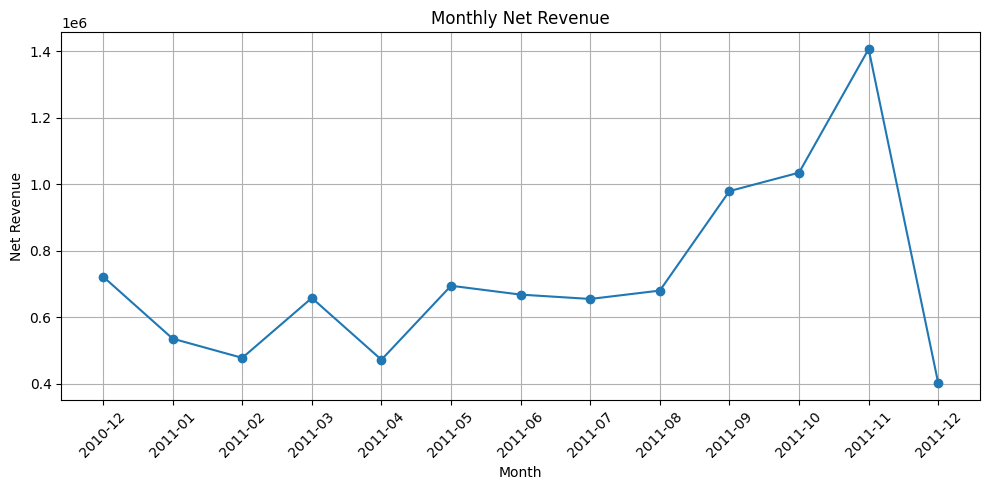

In [17]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_scorecard["month"], monthly_scorecard["revenue"], marker="o")
plt.title("Monthly Net Revenue")
plt.xlabel("Month"); plt.ylabel("Net Revenue")
plt.xticks(rotation=45); plt.grid(True); plt.tight_layout()
plt.show()

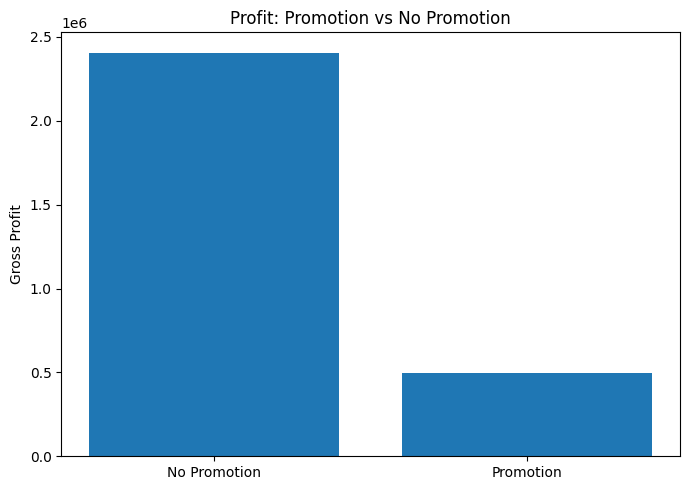

In [18]:
plt.figure(figsize=(7, 5))
plt.bar(promotion_comparison["promotion"], promotion_comparison["profit"])
plt.title("Profit: Promotion vs No Promotion")
plt.ylabel("Gross Profit")
plt.tight_layout()
plt.show()

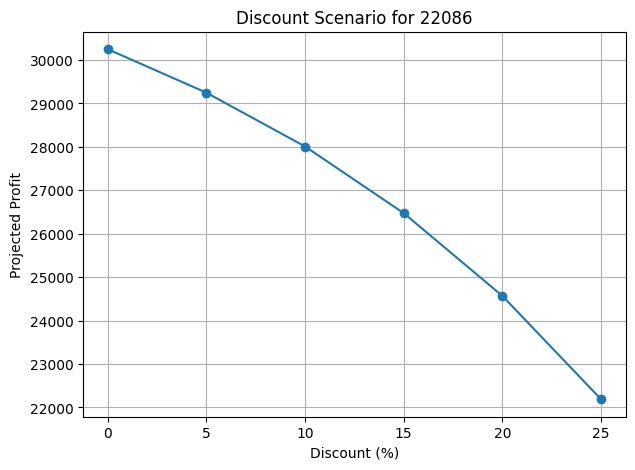

In [19]:
sample_product = scenario_report["product"].iloc[0]
sample = scenario_report[scenario_report["product"] == sample_product]
plt.figure(figsize=(7, 5))
plt.plot(sample["discount_pct"], sample["projected_profit"], marker="o")
plt.title("Discount Scenario for " + str(sample_product))
plt.xlabel("Discount (%)"); plt.ylabel("Projected Profit")
plt.grid(True); plt.show()

## 16. Export reports for college

In [20]:
summary.to_csv("pricing_profit_summary.csv", index=False)
product_scorecard.to_csv("product_scorecard.csv", index=False)
market_scorecard.to_csv("market_scorecard.csv", index=False)
monthly_scorecard.to_csv("monthly_scorecard.csv", index=False)
promotion_comparison.to_csv("promotion_comparison.csv", index=False)
monthly_promo.to_csv("monthly_promotion_comparison.csv", index=False)
scenario_report.to_csv("discount_scenario_report.csv", index=False)
margin_check.to_csv("margin_check.csv", index=False)
print("All report files saved!")

All report files saved!


In [21]:
# Download some main reports to your computer
from google.colab import files
files.download("pricing_profit_summary.csv")
files.download("product_scorecard.csv")
files.download("promotion_comparison.csv")
files.download("discount_scenario_report.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 17. Conclusion for project report
This project analyzed retail transactions to calculate revenue, estimated cost, gross profit and gross margin. It compared simulated promotion and non-promotion groups, summarized results by product, market and month, and tested discount scenarios using an assumed elasticity.

Since cost and promotion details were simulated, the results are examples and not verified business outcomes. A comparison does not prove promotions caused sales changes; causal lift needs reliable promotion records and a controlled experiment or suitable statistical controls.

### Viva questions
1. **Gross profit:** Revenue minus cost of goods sold.
2. **Gross margin:** Profit as a percentage of revenue.
3. **Discount depth:** Discount percentage from the original price.
4. **Price elasticity:** How demand changes when price changes.
5. **Margin erosion:** Profit margin falling due to discounts or higher costs.
6. **Correlation vs causation:** A relationship does not prove one factor caused the other.
7. **Why simulate cost/promotion fields?** The selected public dataset may not contain verified costs or promotion labels, so transparent assumptions were used for demonstration.